# Barça's big-game problem: is it real?

**Question.** Barcelona have dominated La Liga for two decades. But do they still dominate when the opponent is
elite, or does the gap collapse? And if it shrinks, *why*: do elite teams stop Barça creating, or do they carve
Barça open?

**Data.** StatsBomb open event data: **524 Barça La Liga matches, 2004/05 – 2020/21** (every Messi league
appearance StatsBomb has released), plus the full **2015/16 La Liga season** (380 matches) as a benchmark.
Around 3.1 million events, 21,153 shots.

**Elite opposition** = Real Madrid (every season) and Atlético Madrid from 2012/13, when Simeone's side
became a permanent top-three team. That gives **47 elite games** vs **477 others**.

Pipeline: `src/fetch.py` (download) → `src/build_tables.py` (event JSON → tidy parquet) → `sql/queries.sql`
(DuckDB) → this notebook. `src/xg_model.py` trains my own expected-goals model.

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd
from IPython.display import display
import charts
from run_sql import connect, load_queries
from fetch import get_json

con, Q = connect(), load_queries()
df = con.execute('''
    SELECT m.*, b.xg AS xg_for, o.xg AS xg_against, b.xg - o.xg AS xg_diff,
           b.ppda, b.def_action_height, b.field_tilt, b.pass_share, b.high_recoveries
    FROM matches m JOIN barca b USING (match_id) JOIN opp o USING (match_id)
''').df()
shots = pd.read_parquet("../data/processed/shots.parquet")
print(f"{len(df)} Barça matches, {df.elite.sum()} vs elite opposition")

524 Barça matches, 47 vs elite opposition


## 1. The headline: how much does the gap shrink?

In [2]:
con.execute(Q["elite_vs_rest"]).df()

,opposition,games,points_per_game,win_pct,goals_for,goals_against,xg_for,xg_against,xg_diff
0,Elite (RMA / ATM),47,1.81,51.1,1.77,1.15,1.38,1.12,0.26
1,Rest of La Liga,477,2.43,75.9,2.73,0.81,2.07,0.81,1.26


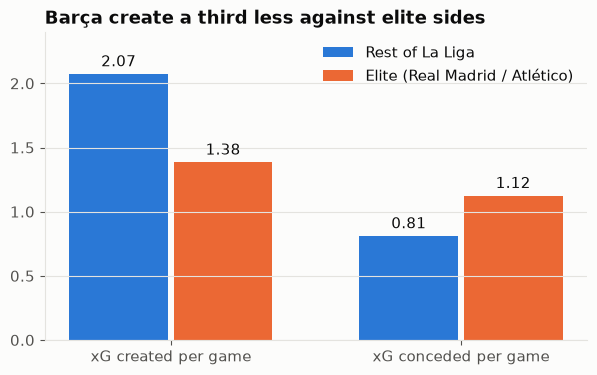

In [3]:
charts.xg_split(df);

Against the rest of La Liga, Barça out-create opponents by **+1.26 xG per game**. Against Real Madrid and
Atlético that falls to **+0.26**: still positive, but four-fifths of the margin is gone. Points per game drop
from 2.43 to 1.81.

**Most of the drop is in attack, not defence.** xG created falls by 0.69 per game (2.07 → 1.38), while xG
conceded rises by only 0.31 (0.81 → 1.12). Elite teams don't mainly carve Barça open. Their main effect
is stopping Barça from creating.

## 2. Is that gap real, or noise from 47 games?

In [4]:
rng = np.random.default_rng(42)
e, r = df[df.elite].xg_diff.values, df[~df.elite].xg_diff.values
gap = r.mean() - e.mean()

# bootstrap 95% CI on the difference in means
boot = [rng.choice(r, len(r)).mean() - rng.choice(e, len(e)).mean() for _ in range(10_000)]
lo, hi = np.percentile(boot, [2.5, 97.5])

# permutation test: how often does a random 47-game split produce a gap this large?
allv = df.xg_diff.values
perm = np.array([(lambda p: allv[p[len(e):]].mean() - allv[p[:len(e)]].mean())(rng.permutation(len(allv)))
                 for _ in range(10_000)])
print(f"Gap in xG difference: {gap:.2f} per game, 95% CI [{lo:.2f}, {hi:.2f}]")
print(f"Permutation p-value: {(perm >= gap).mean():.4f} (10,000 shuffles)")

Gap in xG difference: 1.00 per game, 95% CI [0.70, 1.29]
Permutation p-value: 0.0000 (10,000 shuffles)


The interval is far from zero, and no random shuffle out of 10,000 produced a gap that big. The drop is real.
Home/away balance doesn't explain it either: the elite sample is 22 home and 25 away, close to the rest's
roughly 50/50 split.

## 3. Is that unusual? A benchmark from 2015/16

Any team does worse against stronger opponents, so the question is whether Barça's drop is *bigger than normal*.
2015/16 is the one season where StatsBomb released every La Liga match, so the top three can be compared like for like.

In [5]:
ms = get_json("matches/11/27.json")
teams = {m["match_id"]: (m["home_team"]["home_team_name"], m["away_team"]["away_team_name"]) for m in ms}
xg = shots[shots.match_id.isin(teams)].groupby(["match_id", "team"]).xg_statsbomb.sum()
top3 = ["Barcelona", "Real Madrid", "Atlético Madrid"]
rows = [(t, o in top3, xg.get((mid, t), 0) - xg.get((mid, o), 0))
        for mid, (h, a) in teams.items() for t, o in [(h, a), (a, h)] if t in top3]
bench = pd.DataFrame(rows, columns=["team", "vs_top3", "xg_diff"])
bench = bench.groupby(["team", "vs_top3"]).xg_diff.mean().unstack().round(2)
bench.columns = ["vs rest", "vs other top-3"]
bench["drop"] = bench["vs rest"] - bench["vs other top-3"]
bench.sort_values("drop")

,vs rest,vs other top-3,drop
team,,,
Atlético Madrid,0.76,0.35,0.41
Barcelona,1.69,0.36,1.33
Real Madrid,1.16,-0.71,1.87


In 2015/16 Real Madrid's margin fell by more than Barça's and actually went negative against the other two.
So the drop itself is normal; elite teams do this to everyone. What stands out is that **Barça stayed
positive** against elite opponents across this whole era. Only 4 games per team here, so treat it as context
rather than proof.

## 4. Does the press and the high line survive against elite teams?

In [6]:
con.execute(Q["style_vs_elite"]).df()

,opposition,barca_ppda,barca_def_height,barca_pass_share_pct,barca_field_tilt_pct,barca_high_recoveries,barca_final_third_pressures,opp_offsides_per_game
0,Elite (RMA / ATM),12.33,51.0,62.0,60.7,11.1,28.0,2.26
1,Rest of La Liga,12.46,54.3,66.2,70.6,13.8,29.5,2.43


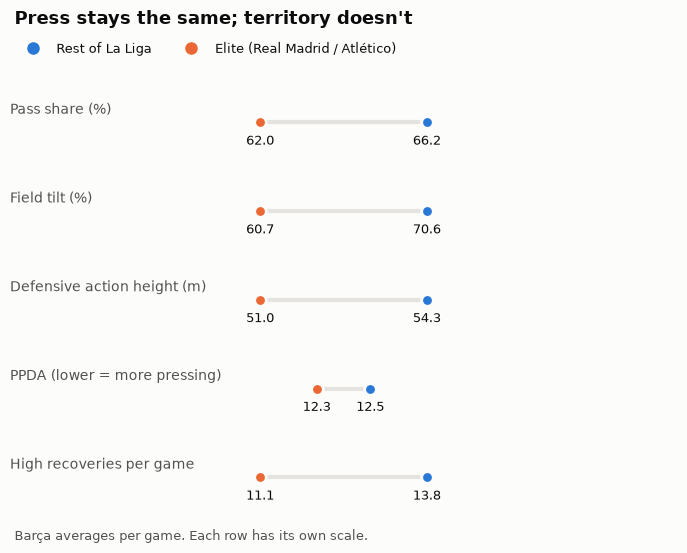

In [7]:
charts.style_dumbbell(df);

In [8]:
for c in ["ppda", "def_action_height", "field_tilt"]:
    a, b = df[~df.elite][c].values, df[df.elite][c].values
    bs = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(5_000)]
    print(f"{c:18s} rest {a.mean():6.2f}  elite {b.mean():6.2f}  95% CI of gap {np.percentile(bs, [2.5, 97.5]).round(2)}")

ppda               rest  12.46  elite  12.33  95% CI of gap [-1.21  1.35]


def_action_height  rest  54.34  elite  51.01  95% CI of gap [1.85 4.81]


field_tilt         rest   0.71  elite   0.61  95% CI of gap [0.06 0.13]


- **The press doesn't change.** PPDA (opponent passes allowed per defensive action) is about 12.4 in both
  groups, and the confidence interval crosses zero. Barça press elite teams just as hard.
- **But they press from further back.** Barça's average defensive action happens about **3.3 m closer to
  their own goal** (54.3 → 51.0 m), and their share of final-third passes falls **10 points** (71% → 61%).
  Elite sides don't escape the press so much as stop it starting high up the pitch.

That fits the attacking drop in section 1: less time in the final third means fewer shots, from worse spots.
The shot map confirms it: 15.8 → 13.3 non-penalty shots per game, the share taken inside the box falls from 63%
to 57%, and the average shot is worth 0.097 xG instead of 0.120. The biggest single loss is the central zone of
the box (5.9 → 4.2 shots per game).

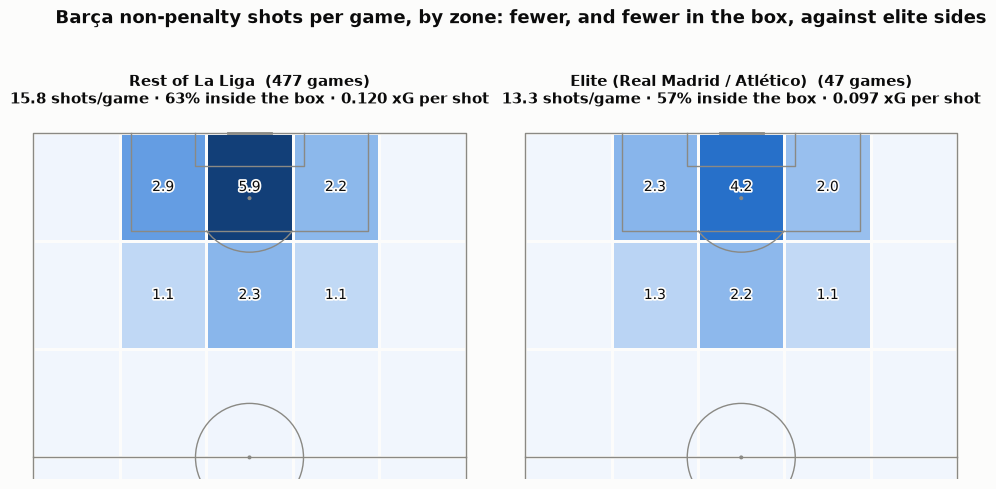

In [9]:
charts.shot_maps(shots, df);

## 5. Myth check: do elite teams kill Barça on the counter?

In [10]:
con.execute(Q["counter_exposure"]).df()

,opposition,opp_counter_xg_per_game,counter_share_of_xg_against_pct,big_chances_conceded,barca_errors_leading_to_shot,barca_red_cards
0,Elite (RMA / ATM),0.069,6.2,0.72,0.11,0.106
1,Rest of La Liga,0.055,6.8,0.54,0.27,0.086


**Not in this era.** Counter-attacks make up a *smaller* share of the xG Barça concede against elite teams
(6.2% vs 6.8%), and Barça make fewer errors leading to shots. What does rise is big chances conceded
(0.54 → 0.72 per game, chances of 0.3 xG or more). Elite teams create better chances, but not mainly through
counters. This doesn't fit the usual story, so it's worth checking against recent Flick-era data (see limitations).

## 6. Across seasons and managers

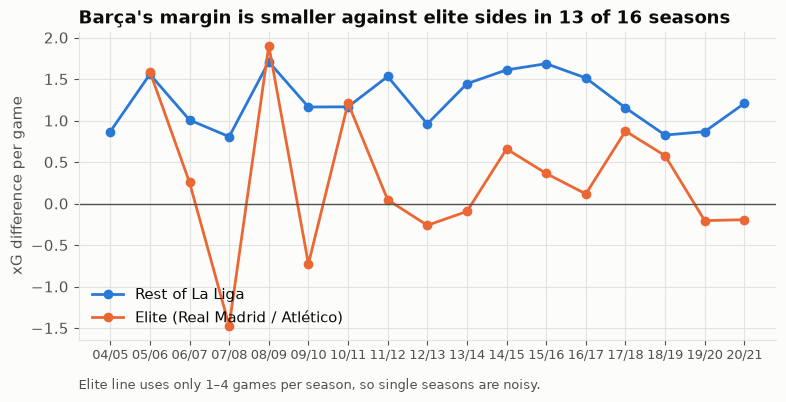

In [11]:
charts.season_trend(df);

In [12]:
con.execute(Q["by_manager"]).df()

,manager,elite_games,xg_diff_rest,xg_diff_elite,elite_drop,ppda_rest,ppda_elite
0,Rijkaard,4,1.04,0.16,-0.89,10.78,10.36
1,Guardiola,8,1.39,0.61,-0.78,11.30,9.82
2,Vilanova,4,0.96,-0.26,-1.22,14.77,10.45
3,Martino,4,1.44,-0.09,-1.54,12.43,10.76
4,Luis Enrique,12,1.61,0.38,-1.23,12.06,11.62
5,Valverde,9,0.95,0.52,-0.43,14.16,15.80
6,Koeman,4,1.21,-0.19,-1.40,15.66,16.77


Barça's margin against elite sides went negative in six of 16 seasons, including the last two in the
data (2019/20, 2020/21). That matches the club's decline at the end of the Messi era. Valverde had the smallest
elite drop, but also the least intense press (PPDA 14–16): his sides were more conservative and less exposed.
Manager samples are tiny (4–12 elite games), so these are hints, not findings.

In [13]:
con.execute(Q["worst_elite_games"]).df()

,date,season,manager,fixture,score,xg_for,xg_against,rank_worst
0,2020-10-24,2020/2021,Koeman,vs Real Madrid,1-3,1.25,2.90,1
1,2008-05-07,2007/2008,Rijkaard,@ Real Madrid,1-4,0.99,2.46,2
2,2013-03-02,2012/2013,Vilanova,@ Real Madrid,1-2,0.34,1.31,3
3,2017-04-23,2016/2017,Luis Enrique,@ Real Madrid,3-2,1.78,2.68,4
4,2010-04-10,2009/2010,Guardiola,@ Real Madrid,2-0,0.66,1.53,5
5,2014-10-25,2014/2015,Luis Enrique,@ Real Madrid,1-3,1.22,2.06,6
6,2018-05-06,2017/2018,Valverde,vs Real Madrid,2-2,1.01,1.77,7
7,2016-04-02,2015/2016,Luis Enrique,vs Real Madrid,1-2,0.73,1.32,8
8,2009-11-29,2009/2010,Guardiola,vs Real Madrid,1-0,0.71,1.29,9
9,2020-06-30,2019/2020,Setién,vs Atlético Madrid,2-2,1.48,1.99,10


## 7. My own expected-goals model

StatsBomb's xG is a black box, so I built my own and benchmarked it against theirs. Features: distance, angle to
goal, header, first-time shot, under pressure, shot type, play pattern and technique, plus two features from the
**freeze frame** (where every player stood at the moment of the shot): defenders inside the shooter-to-posts
triangle, and the goalkeeper's distance from goal. Evaluation is **5-fold cross-validation grouped by match**,
so a game's shots are never in both train and test.

In [14]:
pd.read_csv("../data/processed/xg_model_scores.csv", index_col=0).round(4)

,log_loss,brier,roc_auc,xg_total,goals
statsbomb_xg,0.2858,0.0833,0.8147,2156.3172,2457.0
logistic,0.2917,0.0854,0.8041,2458.4023,2457.0
gradient_boosting,0.2907,0.0851,0.8054,2455.3266,2457.0


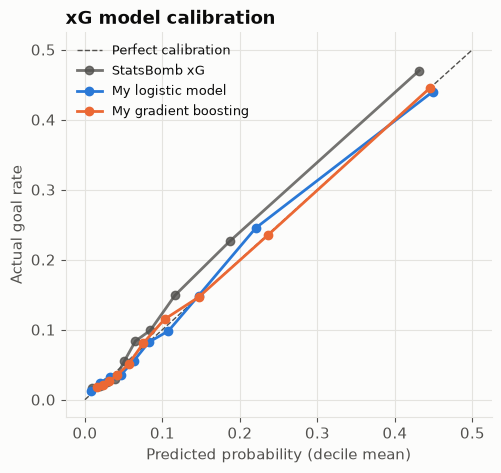

In [15]:
charts.calibration(pd.read_parquet("../data/processed/shots_xg.parquet"));

Both models land within about 2% of StatsBomb's log loss (0.291 vs 0.286) and ROC AUC (0.805 vs 0.815), using
public features only. Gradient boosting barely beats logistic regression, so most of the signal is in a few
geometric features.

One catch: my models total 2,458 xG against 2,457 real goals, while StatsBomb's total is 2,156. My models are
calibrated *to this sample*, and this sample is dominated by Messi-era Barça, who scored about 14% more than
StatsBomb's xG expects. A fair model for all of La Liga would need to be trained on unbiased data.

## Conclusions

1. **The gap is real:** Barça's xG margin falls from +1.26 to +0.26 per game against elite opponents
   (95% CI for the drop 0.70–1.29; p < 0.001).
2. **It's mainly an attacking problem:** about 70% of the drop is xG they stop creating, not extra xG they concede.
3. **The press survives; the territory doesn't:** same PPDA, but defending 3.3 m deeper and 10 points less
   final-third share.
4. **Counters aren't the killer** in this era. Elite sides create better chances, but not mainly on the break.
5. **A drop is normal** (2015/16 Real Madrid fell further). Staying positive against elite teams is what made
   that Barça special, and the 2019–21 seasons are where it disappeared.

## Limitations and next steps
- StatsBomb only released matches Messi played, so it's a selected sample; Flick-era data (2024–26) isn't open.
- "Elite" is a fixed definition; a rolling Elo rating would be a cleaner measure of opponent strength.
- Next: repeat with 360 freeze-frame data to measure the actual height of the back line, and add Champions
  League knockout games, where the big-game story is usually told.